In [1]:
ndx_file = 'data/stat1_wt_nohis_200ns/hbonds_prot.ndx'

In [2]:
import MDAnalysis as mda
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Lists to store hydrogen bond data
hbonds_data = []
current_frame = None

# Parse the .ndx file
with open(ndx_file, 'r') as f:
    lines = f.readlines()
    start_parsing = False
    
    for line in lines:
        line = line.strip()
        
        # Start parsing at [ hbonds_Protein_PTR-DNA_frame_0 ]
        if '[ hbonds_Protein_PTR-DNA_frame_0 ]' in line:
            start_parsing = True
            current_frame = 0
            continue
        
        # Stop parsing if we hit an unrelated section (optional, adjust if needed)
        if start_parsing and line.startswith('[') and 'hbonds_Protein_PTR-DNA_frame' not in line:
            break
        
        if start_parsing:
            # Check if line is a new frame header
            if line.startswith('[ hbonds_Protein_PTR-DNA_frame_'):
                frame_num = int(line.split('_')[-1].replace(' ]', ''))
                current_frame = frame_num
            # Process lines with atom indices
            elif line and not line.startswith('['):
                try:
                    donor, hydrogen, acceptor = map(int, line.split())
                    hbonds_data.append({
                        'donor': donor,
                        'hydrogen': hydrogen,
                        'acceptor': acceptor,
                        'frame': current_frame
                    })
                except ValueError:
                    continue  # Skip malformed lines

In [4]:
df = pd.DataFrame(hbonds_data)
print("Hydrogen Bonds DataFrame:")
print(df.head())

Hydrogen Bonds DataFrame:
   donor  hydrogen  acceptor  frame
0   3148      3149     19526      0
1   3291      3293     19542      0
2   3346      3347     19465      0
3   4019      4020     18674      0
4   4498      4501     18706      0


In [5]:
df.shape

(20719, 4)

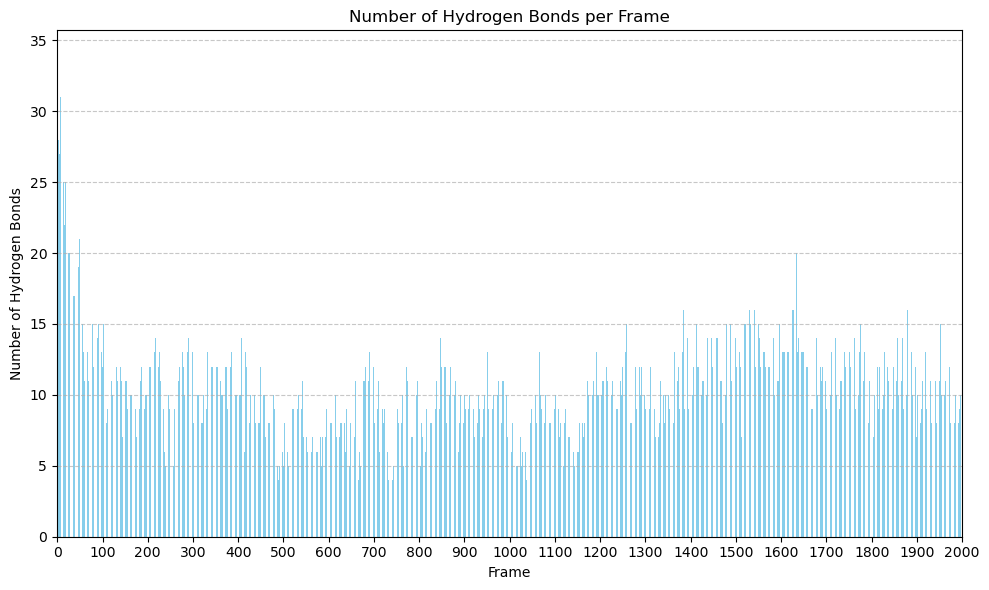

In [6]:
# Step 2: Calculate number of hydrogen bonds per frame
hbonds_per_frame = df.groupby('frame').size()

# Step 3: Plot the number of hydrogen bonds per frame
plt.figure(figsize=(10, 6))
hbonds_per_frame.plot(kind='bar', color='skyblue')
plt.xlabel('Frame')
plt.ylabel('Number of Hydrogen Bonds')
plt.title('Number of Hydrogen Bonds per Frame')
plt.xticks(ticks=np.arange(0, len(hbonds_per_frame), 100), rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [7]:
# Group by the unique bond combination and count occurrences
bond_counts = df.groupby(['donor', 'hydrogen', 'acceptor']).size().reset_index(name='count')

# Get total number of unique frames in the original data
total_frames = df['frame'].nunique()

# Calculate percentage of frames for each bond
bond_counts['frame%'] = (bond_counts['count'] / total_frames) * 100

# Resulting DataFrame with unique bonds and their frame percentages
result_df = bond_counts

result_df.head()

,donor,hydrogen,acceptor,count,frame%
0,3148,3149,19495,15,0.749625
1,3148,3149,19496,1,0.049975
2,3148,3149,19523,3,0.149925
3,3148,3149,19525,74,3.698151
4,3148,3149,19526,6,0.299850


In [8]:
result_df.shape

(616, 5)

In [9]:
result_df.sort_values('frame%', ascending=False).head()

,donor,hydrogen,acceptor,count,frame%
184,4619,4621,19774,1026,51.274363
385,12560,12561,18768,832,41.579210
386,12560,12561,18769,571,28.535732
563,14455,14456,19402,487,24.337831
421,13684,13685,18768,464,23.188406


In [10]:
def get_atom_info(structure_file, file_format='pdb'):
    atom_info = {}
    
    # Open and read the PDB file
    with open(structure_file, 'r') as f:
        for line in f:
            # Check for ATOM or HETATM records
            if line.startswith(('ATOM', 'HETATM')):
                try:
                    # Parse PDB format according to standard columns
                    # https://www.wwpdb.org/documentation/file-format-content/format33/sect9.html
                    atom_id = int(line[6:11].strip())      # Serial number
                    atom_name = line[12:16].strip()        # Atom name
                    res_name = line[17:20].strip()         # Residue name
                    res_num = int(line[22:26].strip())     # Residue sequence number
                    
                    # Store in dictionary
                    atom_info[atom_id] = {
                        'res_name': res_name,
                        'res_num': res_num,
                        'atom_name': atom_name
                    }
                except (ValueError, IndexError):
                    # Skip malformed lines
                    continue
    
    return atom_info

In [11]:
# Get atom information from GRO file
atom_info = get_atom_info('data/stat1_wt_nohis_200ns/md_prot.pdb', file_format='pdb')

# Add donor information
result_df['donor_res_name'] = result_df['donor'].map(lambda x: atom_info.get(x, {}).get('res_name', 'UNK'))
result_df['donor_res_num'] = result_df['donor'].map(lambda x: atom_info.get(x, {}).get('res_num', 'UNK'))
result_df['donor_atom_name'] = result_df['donor'].map(lambda x: atom_info.get(x, {}).get('atom_name', 'UNK'))

# Add acceptor information
result_df['acceptor_res_name'] = result_df['acceptor'].map(lambda x: atom_info.get(x, {}).get('res_name', 'UNK'))
result_df['acceptor_res_num'] = result_df['acceptor'].map(lambda x: atom_info.get(x, {}).get('res_num', 'UNK'))
result_df['acceptor_atom_name'] = result_df['acceptor'].map(lambda x: atom_info.get(x, {}).get('atom_name', 'UNK'))

In [12]:
result_df.sort_values('frame%', ascending=False).head()

,donor,hydrogen,acceptor,count,frame%,donor_res_name,donor_res_num,donor_atom_name,acceptor_res_name,acceptor_res_num,acceptor_atom_name
184,4619,4621,19774,1026,51.274363,ARG,276,NH1,DT,19,O2
385,12560,12561,18768,832,41.579210,GLN,200,N,DC,11,OP1
386,12560,12561,18769,571,28.535732,GLN,200,N,DC,11,OP2
563,14455,14456,19402,487,24.337831,SER,316,OG,DT,8,OP2
421,13684,13685,18768,464,23.188406,GLN,266,NE2,DC,11,OP1


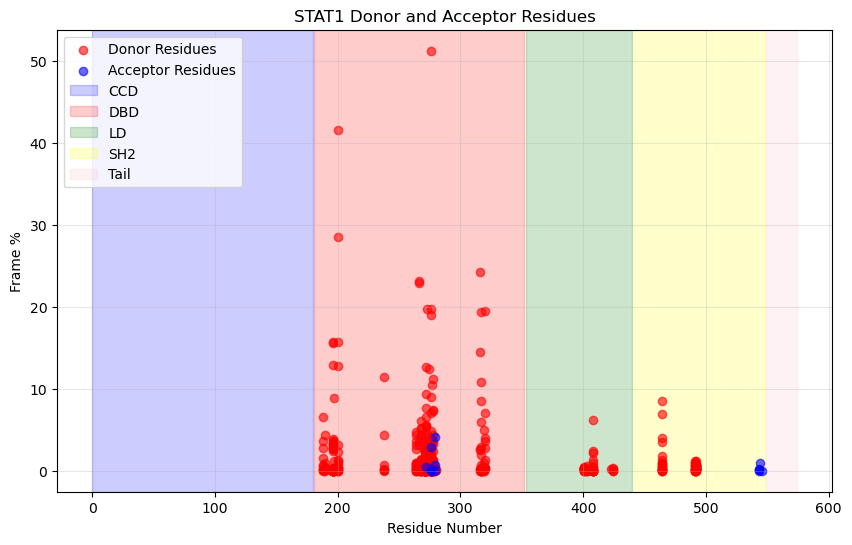

In [13]:
aa_codes = {'ALA', 'ARG', 'ASN', 'ASP', 'CYS', 'GLN', 'GLU', 'GLY', 'HIS', 'ILE',
           'LEU', 'LYS', 'MET', 'PHE', 'PRO', 'SER', 'THR', 'TRP', 'TYR', 'VAL'}

donor_df = result_df[result_df['donor_res_name'].isin(aa_codes)]
acceptor_df = result_df[result_df['acceptor_res_name'].isin(aa_codes)]

# Create the plot
plt.figure(figsize=(10, 6))

# Plot donor residues in red
plt.scatter(donor_df['donor_res_num'], donor_df['frame%'], 
           color='red', label='Donor Residues', alpha=0.6)

# Plot acceptor residues in blue (if any have 3-letter codes)
plt.scatter(acceptor_df['acceptor_res_num'], acceptor_df['frame%'], 
           color='blue', label='Acceptor Residues', alpha=0.6)

# Customize the plot
plt.xlabel('Residue Number')
plt.ylabel('Frame %')
plt.title('STAT1 Donor and Acceptor Residues')
plt.grid(True, alpha=0.3)


plt.axvspan(0, 180, zorder=0, alpha=0.2, color='blue', label='CCD')
plt.axvspan(181, 352, zorder=0, alpha=0.2, color='red', label='DBD')
plt.axvspan(353, 440, zorder=0, alpha=0.2, color='green', label='LD')
plt.axvspan(441, 548, zorder=0, alpha=0.2, color='yellow', label='SH2')
plt.axvspan(549, 574, zorder=0, alpha=0.2, color='pink', label='Tail')

plt.legend()

# Show the plot
plt.show()

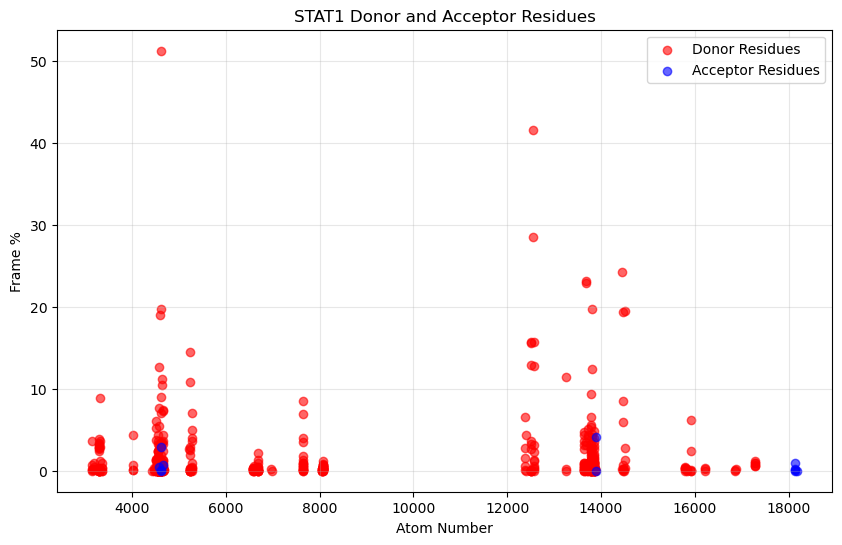

In [14]:
# Create the plot
plt.figure(figsize=(10, 6))

# Plot donor residues in red
plt.scatter(donor_df['donor'], donor_df['frame%'], 
           color='red', label='Donor Residues', alpha=0.6)

# Plot acceptor residues in blue
plt.scatter(acceptor_df['acceptor'], acceptor_df['frame%'], 
           color='blue', label='Acceptor Residues', alpha=0.6)

# Customize the plot
plt.xlabel('Atom Number')
plt.ylabel('Frame %')
plt.title('STAT1 Donor and Acceptor Residues')
plt.grid(True, alpha=0.3)

plt.legend()

# Show the plot
plt.show()

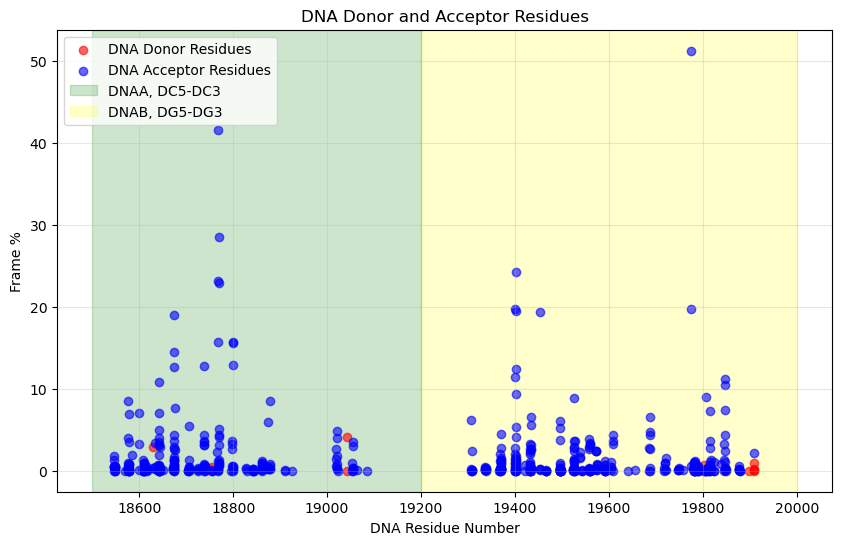

In [15]:
dna_codes = {'DG', 'DT', 'DA', 'DC', 'DG5', 'DC5','DC3', 'DG3'}

# Filter for DNA donors and acceptors
dna_donor_df = result_df[result_df['donor_res_name'].isin(dna_codes)]
dna_acceptor_df = result_df[result_df['acceptor_res_name'].isin(dna_codes)]

# Create the plot
plt.figure(figsize=(10, 6))

# Plot DNA donor residues in red using donor atom numbers
plt.scatter(dna_donor_df['donor'], dna_donor_df['frame%'], 
           color='red', label='DNA Donor Residues', alpha=0.6)

# Plot DNA acceptor residues in blue using acceptor atom numbers
plt.scatter(dna_acceptor_df['acceptor'], dna_acceptor_df['frame%'], 
           color='blue', label='DNA Acceptor Residues', alpha=0.6)

plt.axvspan(18500, 19200, zorder=0, alpha=0.2, color='green', label="DNAA, DC5-DC3")
plt.axvspan(19201, 20000, zorder=0, alpha=0.2, color='yellow', label="DNAB, DG5-DG3")

# Customize the plot
plt.xlabel('DNA Residue Number')
plt.ylabel('Frame %')
plt.title('DNA Donor and Acceptor Residues')
plt.grid(True, alpha=0.3)
plt.legend()

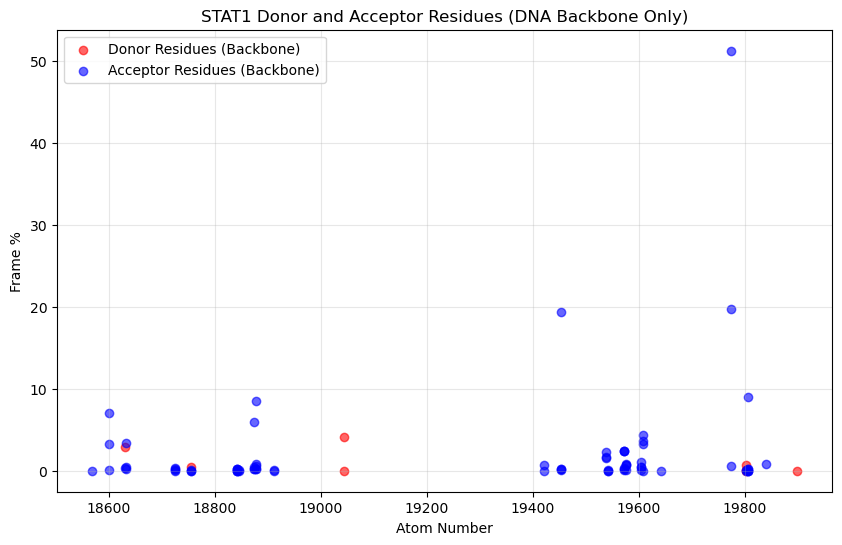

In [17]:
# Define backbone atom criteria
backbone_atoms = {'P', 'OP1', 'OP2'}  # Phosphate atoms without prime
def is_backbone_atom(atom_name):
    # Check if atom is P, OP1, OP2 or contains a prime
    return atom_name in backbone_atoms or "'" in atom_name

# Filter donor_df for backbone donors
donor_df_backbone = dna_donor_df [~dna_donor_df['donor_atom_name'].apply(is_backbone_atom)]

# Filter acceptor_df for backbone acceptors
acceptor_df_backbone = dna_acceptor_df[~dna_acceptor_df['acceptor_atom_name'].apply(is_backbone_atom)]

# Create the plot
plt.figure(figsize=(10, 6))

# Plot donor residues in red (backbone only)
plt.scatter(donor_df_backbone['donor'], donor_df_backbone['frame%'], 
            color='red', label='Donor Residues (Backbone)', alpha=0.6)

# Plot acceptor residues in blue (backbone only)
plt.scatter(acceptor_df_backbone['acceptor'], acceptor_df_backbone['frame%'], 
            color='blue', label='Acceptor Residues (Backbone)', alpha=0.6)

# Customize the plot
plt.xlabel('Atom Number')
plt.ylabel('Frame %')
plt.title('STAT1 Donor and Acceptor Residues (DNA Backbone Only)')
plt.grid(True, alpha=0.3)
plt.legend()

# Show the plot
plt.show()